<a href="https://colab.research.google.com/github/nagarjuna-32/python-practice/blob/main/brain_Tumar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install tensorflow

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [ ]:
import os
import kagglehub
path = kagglehub.dataset_download("tombackert/brain-tumor-mri-data")
print(path)

Using Colab cache for faster access to the 'brain-tumor-mri-data' dataset.
/kaggle/input/brain-tumor-mri-data


In [ ]:
for root, floders,files in os.walk(path):
  print(root)

/kaggle/input/brain-tumor-mri-data
/kaggle/input/brain-tumor-mri-data/brain-tumor-mri-dataset
/kaggle/input/brain-tumor-mri-data/brain-tumor-mri-dataset/pituitary
/kaggle/input/brain-tumor-mri-data/brain-tumor-mri-dataset/notumor
/kaggle/input/brain-tumor-mri-data/brain-tumor-mri-dataset/meningioma
/kaggle/input/brain-tumor-mri-data/brain-tumor-mri-dataset/glioma


In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32

In [ ]:
train_datagen = ImageDataGenerator(
    rescale = 1./255,
    validation_split = 0.2)

In [ ]:
train_generator = train_datagen.flow_from_directory(
    os.path.join(path, "brain-tumor-mri-dataset"),
    target_size = (IMG_SIZE,IMG_SIZE),
    batch_size = BATCH_SIZE,
    class_mode = 'categorical',
    subset = 'training'
)

Found 5723 images belonging to 4 classes.


In [ ]:
validation_generator = train_datagen.flow_from_directory(
    path+  "/brain-tumor-mri-dataset",
    target_size = (IMG_SIZE,IMG_SIZE),
    batch_size = BATCH_SIZE,
    class_mode = 'categorical',
    subset = 'validation'
)

Found 1430 images belonging to 4 classes.


In [ ]:
print(train_generator.class_indices)

{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


In [ ]:
model = keras.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(4, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,476 (42.61 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [ ]:
model.fit(train_generator, epochs=10, validation_data=validation_generator,batch_size=BATCH_SIZE)

Epoch 1/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 28s 155ms/step - accuracy: 0.9972 - loss: 0.0066 - val_accuracy: 0.9126 - val_loss: 0.5245
Epoch 2/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 28s 159ms/step - accuracy: 0.9878 - loss: 0.0336 - val_accuracy: 0.9350 - val_loss: 0.3493
Epoch 3/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 29s 160ms/step - accuracy: 0.9928 - loss: 0.0245 - val_accuracy: 0.9343 - val_loss: 0.3408
Epoch 4/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 27s 149ms/step - accuracy: 0.9984 - loss: 0.0053 - val_accuracy: 0.9483 - val_loss: 0.3126
Epoch 5/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 28s 158ms/step - accuracy: 1.0000 - loss: 1.6126e-04 - val_accuracy: 0.9476 - val_loss: 0.3342
Epoch 6/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 28s 155ms/step - accuracy: 1.0000 - loss: 8.4085e-05 - val_accuracy: 0.9476 - val_loss: 0.3487
Epoch 7/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 28s 156ms/step - accuracy: 1.0000 - loss: 5.8079e-05 - val_accuracy: 0.9455 - val_loss: 0.3613
Epoch 8/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 27s 150ms/step - accuracy: 1.00

In [ ]:
model.save("Braintumor_multi.h5")

In [ ]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import numpy as np
model = load_model('Braintumor_multi.h5')
print("model loaded")

model loaded


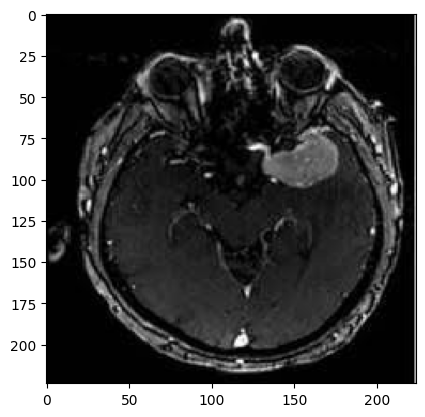

In [ ]:
test_image_path = "/content/brain image .jpeg"
img = image.load_img(test_image_path, target_size=(IMG_SIZE, IMG_SIZE))
plt.imshow(img)
plt.axis()
plt.show()

In [ ]:
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array /= 255

In [ ]:
#make predictions
predictions = model.predict(img_array)
print(predictions)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
[[1.4646608e-20 1.0000000e+00 4.5819002e-15 7.2160478e-14]]


In [ ]:
class_names =train_generator.class_indices
print(class_names)

{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


In [ ]:
final_ind = np.argmax(predictions[0])
print(class_names)
print(final_ind)


{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
1


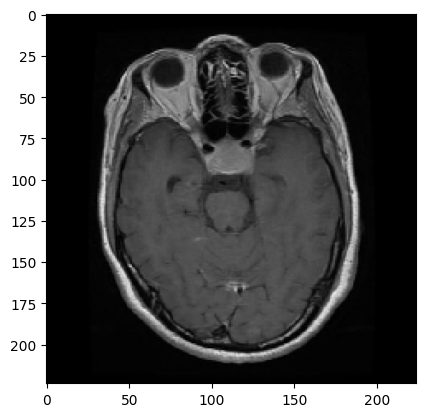

In [ ]:
#load and view the test image
test_image_path = "/content/br2.42.07 PM.jpeg"
img = image.load_img(test_image_path, target_size=(IMG_SIZE, IMG_SIZE))
plt.imshow(img)
plt.axis()
plt.show()

In [ ]:
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array /= 255

In [ ]:
predictions = model.predict(img_array)
print(predictions)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
[[5.6351395e-17 2.2880839e-08 1.3643964e-09 1.0000000e+00]]


In [ ]:
class_names = train_generator.class_indices
print(class_names)

{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


In [ ]:
final_ind = np.argmax(predictions[0])
print(class_names)
print(final_ind)


{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
3


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("adityamahimkar/iqothnccd-lung-cancer-dataset")

print("Path to dataset files:", path)